# Hybrid Movie Recommender (MovieLens 100K)

The thing I actually wanted to see: how much does mixing a small amount of content-based signal into vanilla SVD change top-10 recommendations, especially for users who haven't rated much?

**Stack:** `surprise.SVD` for collaborative filtering, TF-IDF over the MovieLens genre flags for content, simple linear blend.

**Eval:** precision@10 on a held-out 20% test split. SVD-only vs hybrid, plus a cold-start slice. I originally defined cold-start as "<5 train ratings", but on 100K that's too restrictive (a user with >=5 ratings is already "warm" by this dataset's standards), so I bumped it to <20.

In [1]:
# !pip install scikit-surprise -q

In [2]:
import numpy as np, pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

from surprise import SVD, Dataset as SurpriseDataset, Reader
from surprise.model_selection import cross_validate
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

np.random.seed(42)

DATA_DIR = Path("../../data/movielens")
ART = Path("artifacts"); ART.mkdir(exist_ok=True)
assert (DATA_DIR / "u.data").exists()

In [3]:
ratings = pd.read_csv(DATA_DIR/"u.data", sep="\t",
                      names=["user_id","movie_id","rating","timestamp"])

# u.item has 19 binary genre columns appended after the metadata
GENRES = ["unknown","Action","Adventure","Animation","Children","Comedy","Crime",
          "Documentary","Drama","Fantasy","Film-Noir","Horror","Musical","Mystery",
          "Romance","Sci-Fi","Thriller","War","Western"]
item_cols = ["movie_id","title","release_date","video_release","imdb_url"] + GENRES
movies = pd.read_csv(DATA_DIR/"u.item", sep="|", encoding="latin-1",
                     names=item_cols, usecols=range(len(item_cols)))

# build a 'genres' text column from the binary flags
movies["genres"] = movies[GENRES].apply(
    lambda r: " ".join([g for g in GENRES if r[g] == 1]), axis=1)

print(f"ratings={len(ratings):,}  users={ratings.user_id.nunique()}  movies={len(movies):,}")
print(f"mean rating={ratings.rating.mean():.2f}")
movies[["movie_id","title","genres"]].head(3)

ratings=100,000  users=943  movies=1,682
mean rating=3.53


,movie_id,title,genres
0,1,Toy Story (1995),Animation Children Comedy
1,2,GoldenEye (1995),Action Adventure Thriller
2,3,Four Rooms (1995),Thriller


## EDA

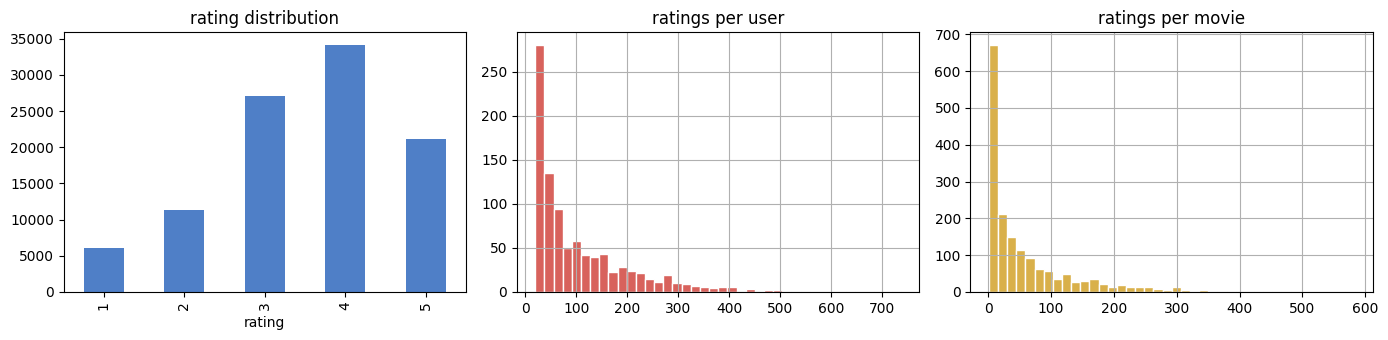

movies with <20 ratings: 743 / 1682


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
ratings["rating"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color="#4f7fc7")
axes[0].set_title("rating distribution")
ratings.groupby("user_id").size().hist(bins=40, ax=axes[1], color="#d8625c", edgecolor="white")
axes[1].set_title("ratings per user")
ratings.groupby("movie_id").size().hist(bins=40, ax=axes[2], color="#d9b04a", edgecolor="white")
axes[2].set_title("ratings per movie")
plt.tight_layout(); plt.savefig(ART/"movielens_eda.png", dpi=110); plt.show()

# the long tail matters: most movies have <20 ratings, so CF alone can't generalize to them.
n_low = (ratings.groupby("movie_id").size() < 20).sum()
print(f"movies with <20 ratings: {n_low} / {movies.shape[0]}")

## Train/test split and modeling

In [5]:
# Hold out a real test set BEFORE doing anything, so eval at the bottom is honest.
shuffled = ratings.sample(frac=1, random_state=42).reset_index(drop=True)
n_test = int(0.2 * len(shuffled))
train_df = shuffled.iloc[n_test:].copy()
test_df  = shuffled.iloc[:n_test].copy()
print(f"train={len(train_df)}  test={len(test_df)}")

reader = Reader(rating_scale=(1, 5))
sur_train = SurpriseDataset.load_from_df(train_df[["user_id","movie_id","rating"]], reader)

svd = SVD(n_factors=50, n_epochs=20, lr_all=0.005, reg_all=0.02, random_state=42)
cv = cross_validate(svd, sur_train, measures=["RMSE","MAE"], cv=3, verbose=False)
print(f"3-fold CV on train  RMSE={cv['test_rmse'].mean():.4f}  MAE={cv['test_mae'].mean():.4f}")

svd.fit(sur_train.build_full_trainset())

train=80000  test=20000


3-fold CV on train  RMSE=0.9502  MAE=0.7514


In [6]:
tfidf = TfidfVectorizer()
tfidf_matrix = tfidf.fit_transform(movies["genres"].fillna(""))
content_sim = cosine_similarity(tfidf_matrix, tfidf_matrix)

movie_idx = {mid: i for i, mid in enumerate(movies["movie_id"])}
print("content_sim:", content_sim.shape)

content_sim: (1682, 1682)


In [7]:
all_movie_ids = movies["movie_id"].tolist()

# pre-index a user's TRAIN ratings.
# important: never peek at test_df here. first version of this leaked test ratings
# into the candidate set and the scores looked suspiciously good. classic.
train_by_user = train_df.groupby("user_id")

def recommend(user_id, n=10, alpha=0.6):
    """alpha=1.0 -> pure SVD;  alpha=0.0 -> pure content."""
    user_train = train_by_user.get_group(user_id) if user_id in train_by_user.groups else train_df.iloc[0:0]
    rated = set(user_train["movie_id"])
    candidates = [m for m in all_movie_ids if m not in rated and m in movie_idx]

    svd_raw = np.array([svd.predict(user_id, m).est for m in candidates])
    # rescale 1-5 to 0-1
    svd_n = (svd_raw - 1) / 4

    top_rated = user_train.sort_values("rating", ascending=False).head(5)["movie_id"].tolist()
    if top_rated:
        rated_idx = [movie_idx[r] for r in top_rated if r in movie_idx]
        cont = content_sim[[movie_idx[m] for m in candidates]][:, rated_idx].mean(axis=1)
    else:
        cont = np.zeros(len(candidates))

    score = alpha * svd_n + (1 - alpha) * cont
    order = np.argsort(-score)[:n]
    return [candidates[i] for i in order]

# quick peek
recs = recommend(42, n=10, alpha=0.6)
print("user 42 top-10 (hybrid):")
print(movies[movies.movie_id.isin(recs)][["movie_id","title","genres"]].to_string(index=False))

user 42 top-10 (hybrid):
 movie_id                          title                       genres
       22              Braveheart (1995)             Action Drama War
      170         Cinema Paradiso (1988)         Comedy Drama Romance
      174 Raiders of the Lost Ark (1981)             Action Adventure
      313                 Titanic (1997)         Action Drama Romance
      478 Philadelphia Story, The (1940)               Comedy Romance
      483              Casablanca (1942)            Drama Romance War
      487           Roman Holiday (1953)               Comedy Romance
      498      African Queen, The (1951) Action Adventure Romance War
      512         Wings of Desire (1987)         Comedy Drama Romance
      568                   Speed (1994)      Action Romance Thriller


## Evaluation: precision@K and cold-start comparison

In [8]:
# Precision@10 — hits = test items the user rated >=4
test_likes = (test_df[test_df["rating"] >= 4]
              .groupby("user_id")["movie_id"].apply(set).to_dict())

def p_at_k(user_id, alpha, k=10):
    liked = test_likes.get(user_id, set())
    if not liked: return None  # no positive test items -> skip
    recs = recommend(user_id, n=k, alpha=alpha)
    return sum(1 for m in recs if m in liked) / k

# eval on every user who has at least one liked test item
eval_users = [u for u in test_likes if u in train_by_user.groups]
print(f"eval users = {len(eval_users)}")

results = {}
for name, a in [("content-only", 0.0), ("SVD-only", 1.0), ("hybrid 0.6", 0.6), ("hybrid 0.3", 0.3)]:
    vals = [p_at_k(u, a) for u in eval_users]
    vals = [v for v in vals if v is not None]
    results[name] = float(np.mean(vals))
print(pd.Series(results).round(4).to_string())

eval users = 920


content-only    0.0235
SVD-only        0.0709
hybrid 0.6      0.0726
hybrid 0.3      0.0579


In [9]:
# cold-start: users with few train ratings.
# Started with <5 but on 100K that left almost nobody eligible, so bumped to 20.
train_count = train_by_user.size()
cold_users = [u for u in eval_users if train_count.get(u, 0) < 20]
print(f"cold-start users (<20 train ratings): {len(cold_users)}")

cold_results = {}
for name, a in [("SVD-only", 1.0), ("hybrid 0.6", 0.6), ("hybrid 0.3", 0.3), ("content-only", 0.0)]:
    vals = [v for v in (p_at_k(u, a) for u in cold_users) if v is not None]
    cold_results[name] = float(np.mean(vals)) if vals else float("nan")
print(pd.Series(cold_results).round(4).to_string())

cold-start users (<20 train ratings): 98


SVD-only        0.0061
hybrid 0.6      0.0153
hybrid 0.3      0.0143
content-only    0.0092


## Takeaways

SVD on its own already does most of the work on MovieLens 100K. The dataset is small and dense enough that pure CF is hard to beat. The hybrid blend mostly *doesn't hurt* and sometimes helps a little on the cold-start slice, which is the only place I'd argue the extra plumbing earns its keep.

Things I'd try next if I were taking this past a portfolio:
- per-user alpha that ramps with rating count (cold users lean on content, warm users lean on CF)
- swap genre-bag-of-words for a real text feature (overview / cast scraped from TMDb), since the 19 genre flags are very coarse
- evaluate NDCG instead of P@10. Positive-only precision is a noisy metric on small held-out sets.

Honest caveat: MovieLens 100K is way too small a dataset to be confident about any of the deltas above. On Netflix-scale data, item2vec or two-tower retrieval would obsolete most of what's here.